## Analysing snippets

In [ ]:
import pandas as pd
from driver import clean_text, get_text_stats
import numpy as np
import re

results_navigation = pd.read_csv("Data/results_navigation.csv")
results_navigation["timestamp"] = pd.to_datetime(results_navigation["timestamp"])

views_df = pd.read_csv("Data/viewed_results_df.csv")
views_df = views_df.loc[views_df["viewType"]=="resultExposureEnded"]

results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: clean_text(x))
# results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: re.sub(
#     r'^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{1,2},\s+\d{4}\s*(?:\.\.\.)?\s*',
#     '',
#     x,
#     flags=re.IGNORECASE
# ))
results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: x.strip())
results_navigation["SERP_result"] = [str(title).strip()+snippet for title, snippet in zip(results_navigation["title"], results_navigation["snippet"])]

text_stat_results = get_text_stats(results_navigation, "SERP_result")

results_navigation["SERP_result_content_len"] = text_stat_results["content_len"]
results_navigation["SERP_result_mean_aoa"] = text_stat_results["mean_aoa"]
results_navigation["SERP_result_mean_conc"] = text_stat_results["mean_conc"]
results_navigation["SERP_result_gulpease_index"] = text_stat_results["gulpease_index"]
# results_navigation["snippet_fres"] = text_stat_results["fres"]

view_count = []
for _, row in results_navigation.iterrows():
    views = views_df.loc[(views_df["serp_id"]==row["serp_id"])&(views_df["rank"]==row["rank"])]
    view_count.append(len(views))
results_navigation["view_count"] = view_count
results_navigation.to_csv("Data/results_navigation.csv", index=False, encoding="utf8")

  0%|          | 0/930 [00:00<?, ?it/s]

In [2]:
results_navigation.to_csv("Data/results_navigation.csv", index=False, encoding='utf8')

In [3]:
results_navigation.loc[pd.isna(results_navigation["rank"])]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index


## Analysing navigation

In [23]:
import pandas as pd

# nlp = spacy.load("it_core_news_lg")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])

serp_df = pd.read_csv("Data/results_navigation.csv")
serp_df["timestamp"] = pd.to_datetime(serp_df["timestamp"])

query_df = pd.read_csv("Data/query_df.csv")
query_df["timestamp"] = pd.to_datetime(query_df["timestamp"])

click_df = pd.read_csv("Data/clicked_results_df.csv")
click_df["timestamp"] = pd.to_datetime(click_df["timestamp"])

view_df = pd.read_csv("Data/viewed_results_df.csv")
view_df["timestamp"] = pd.to_datetime(view_df["timestamp"])
view_df["associated_click_timestamp"] = pd.to_datetime(view_df["associated_click_timestamp"])

In [24]:
serp_df.head()

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index,view_count
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","Oct 31, 2023 ... La fauna selvatica dell'India...",1,1,2,2026-05-19 14:51:27.687,"India naturalistica, 5 animali da non perdere ...",34,6.270000,7.875000,58.022989,3
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","Feb 17, 2017 ... O dei Giganti, vista la mole ...",2,1,0,2026-05-19 14:51:27.688,"Natura selvaggia in India, tra tigri e leoni -...",36,6.864000,5.666667,66.250000,3
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","Jun 5, 2023 ... Sono note cinque metropoli, tr...",3,0,0,2026-05-19 14:51:27.689,"La civiltà dell'Indo, i misteri di un popolo d...",32,NaN,NaN,65.363636,3
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","Jun 6, 2024 ... Chi sono, da dove vengono e qu...",4,0,0,2026-05-19 14:51:27.690,"Chi sono gli Indiani d'America, i nativi ameri...",33,NaN,NaN,61.536765,2
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,Il dolce tipico per celebrare questo giorno è ...,5,0,0,2026-05-19 14:51:27.691,Festa della mamma: come si festeggia nel resto...,37,3.914286,7.200000,64.444015,1


In [25]:
navigation_quality["serp_id"].unique()

array(['serp1', 'serp2', 'serp3', 'serp4', 'serp5', 'serp6', 'serp7',
       'serp8', 'serp9', 'serp10', 'serp11', 'serp12', 'serp13', 'serp14',
       'serp15', 'serp16', 'serp17', 'serp18', 'serp19', 'serp22',
       'serp23', 'serp27', 'serp28', 'serp30', 'serp31', 'serp32',
       'serp33', 'serp34', 'serp35', 'serp36', 'serp37', 'serp38',
       'serp39', 'serp40', 'serp41', 'serp42', 'serp43', 'serp44',
       'serp45', 'serp50', 'serp51', 'serp52', 'serp53', 'serp54',
       'serp55', 'serp56', 'serp57', 'serp59', 'serp60', 'serp61',
       'serp62', 'serp63', 'serp64', 'serp65', 'serp66', 'serp67',
       'serp68', 'serp69', 'serp70', 'serp71', 'serp72', 'serp73',
       'serp74', 'serp75', 'serp78', 'serp79', 'serp80', 'serp81',
       'serp82', 'serp83', 'serp84', 'serp85', 'serp86', 'serp87',
       'serp88', 'serp89', 'serp90', 'serp91', 'serp92', 'serp93',
       'serp95', 'serp96', 'serp97', 'serp99', 'serp100', 'serp101',
       'serp102', 'serp103', 'serp104', 'serp105'

In [26]:
view_df["serp_id"].unique()

array(['serp1', 'serp2', 'serp3', 'serp4', 'serp5', 'serp6', 'serp7',
       'serp8', 'serp9', 'serp10', 'serp11', 'serp12', 'serp13', 'serp14',
       'serp15', 'serp16', 'serp17', 'serp18', 'serp19', 'serp22',
       'serp23', 'serp27', 'serp28', 'serp30', 'serp31', 'serp32',
       'serp33', 'serp34', 'serp36', 'serp37', 'serp38', 'serp39',
       'serp40', 'serp41', 'serp42', 'serp43', 'serp44', 'serp45',
       'serp50', 'serp51', 'serp52', 'serp53', 'serp54', 'serp55',
       'serp56', 'serp57', 'serp59', 'serp60', 'serp61', 'serp62',
       'serp63', 'serp64', 'serp65', 'serp66', 'serp67', 'serp68',
       'serp69', 'serp70', 'serp71', 'serp72', 'serp73', 'serp74',
       'serp75', 'serp78', 'serp79', 'serp80', 'serp81', 'serp82',
       'serp83', 'serp84', 'serp85', 'serp86', 'serp87', 'serp88',
       'serp89', 'serp90', 'serp91', 'serp92', 'serp93', 'serp95',
       'serp96', 'serp97', 'serp99', 'serp100', 'serp101', 'serp102',
       'serp103', 'serp104', 'serp105', 'serp106

In [27]:
serp_id = "serp78"
viewed_results = view_df.loc[(view_df["serp_id"]==serp_id) & (view_df["viewType"]=="resultExposureEnded")]
serp_results = serp_df.loc[serp_df["serp_id"]==serp_id]

unique_viewed_results = serp_results.loc[serp_results["url"].isin(viewed_results["url"].unique())]
unique_viewed_results

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index,view_count
571,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.media.inaf.it/2014/03/12/un-consig...,Un Consiglio dei Giganti per il Gruppo Locale ...,"Mar 12, 2014 ... ... 3 milioni di anni luce. ....",1,1,0,2026-05-19 11:17:33.552,Un Consiglio dei Giganti per il Gruppo Locale ...,33,5.000000,7.050000,66.799043,1
572,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.focus.it/scienza/spazio/la-via-lat...,La Via Lattea e Andromeda sono davvero sorelle...,"Sep 12, 2015 ... La galassia di Andromeda (M 3...",2,1,0,2026-05-19 11:17:33.559,La Via Lattea e Andromeda sono davvero sorelle...,35,NaN,NaN,68.135338,1
573,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://123stella.astronomiamo.it/Fase.aspx?Ar...,Cosa sono le galassie - 123Stella,"Oct 19, 2015 ... 3... STELLAAAAAAA!!! L'univer...",3,0,0,2026-05-19 11:17:33.568,"Cosa sono le galassie - 123StellaOct 19, 2015 ...",30,3.200000,8.250000,71.455357,2
574,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.castfvg.it/galassie/gruppo_locale/...,Il Gruppo Locale,Si pone ad una distanza di oltre mezzo milione...,4,1,0,2026-05-19 11:17:33.581,Il Gruppo LocaleSi pone ad una distanza di olt...,33,6.000000,NaN,64.514706,1
575,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://spaziotempo.altervista.org/gruppo-locale/,Gruppo Locale | Spazio Tempo - Altervista,Gruppo Locale è il nome proprio dato al gruppo...,5,1,0,2026-05-19 11:17:33.589,Gruppo Locale | Spazio Tempo - AltervistaGrupp...,32,5.697143,4.325000,62.161765,1
578,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.focusjunior.it/content/uploads/sit...,"SP ""Aldo Moro"" - Focus Junior","May 30, 2016 ... 3. Una donna tra le stelle: M...",8,0,0,2026-05-19 11:17:33.624,"SP ""Aldo Moro"" - Focus JuniorMay 30, 2016 ... ...",28,4.213333,7.883333,84.924765,1
579,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.focusjunior.it/scienza/spazio/stel...,Quante stelle si possono vedere di notte? - Fo...,"Jun 26, 2024 ... Un numero enorme, ma ancora p...",9,0,0,2026-05-19 11:17:33.630,Quante stelle si possono vedere di notte? - Fo...,32,4.960000,5.500000,76.500000,1
580,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.focusjunior.it/news/i-musei-scient...,"I musei scientifici più curiosi d'Italia, qual...",Abbiamo fatto il giro d'Italia alla scoperta d...,10,0,0,2026-05-19 11:17:33.637,"I musei scientifici più curiosi d'Italia, qual...",33,7.040000,NaN,61.561670,1
581,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://www.focusjunior.it/interviste/intervis...,"Intervista Ilaria Lucrezia Rossi, la fisica ch...","Sep 1, 2025 ... “Per me sono le materie più af...",11,0,0,2026-05-19 11:17:49.331,"Intervista Ilaria Lucrezia Rossi, la fisica ch...",37,6.420000,5.425000,63.210526,1
582,12,g4t3,q78,3 galassie oltre alla nostra,serp78,https://astroscopehub.com/nomi-di-galassie/,Nomi di Galassie: 20 Galassie Più Belle e Affa...,"Jan 10, 2024 ... È una delle galassie più vici...",12,1,1,2026-05-19 11:17:49.343,Nomi di Galassie: 20 Galassie Più Belle e Affa...,33,NaN,NaN,65.410714,1


In [28]:
import numpy as np

first_click_time = [] # time from query entry to first click
click_counts = [] # number of clicks made on a SERP
avg_scroll_time_before_click = [] # how much time is spent scrolling on SERP before a click
click_depth = [] # rank of the lowest clicked result
# avg_snippet_dwell_time = [] # average time for which a snippet is viewed at a time 
rank_lowest_view = [] # rank of the lowest viewed result
avg_snippet_view_counts_before_click = [] # average number of times a user views a snippet before making a click
avg_snippet_dwell_time_before_click = [] # average time a user dwells on a snippet at a time prior to making a click

# average text stats of all SERP results
SERP_total_results = []
SERP_highest_rel_result = []
SERP_avg_aoa = []
SERP_avg_conc = []
SERP_avg_length = []
SERP_avg_gulpease_index = []

# average text stats of all non-viewed results
no_view_avg_aoa = []
no_view_avg_conc = []
no_view_avg_length = []
no_view_avg_gulpease_index = []
no_view_results_ratio = [] # what ratio of serp results was never viewed


# average text stats of all viewed results
viewed_avg_aoa = []
viewed_avg_conc = []
viewed_avg_length = []
viewed_avg_gulpease_index = []

for serp_id in navigation_quality["serp_id"]:
    query_temp_df = query_df.loc[query_df["serp_id"] == serp_id] # query that yielded the SERP
    click_temp_df = click_df.loc[click_df["serp_id"] == serp_id] # all the clicks done on this SERP
    serp_temp_df = serp_df.loc[serp_df["serp_id"]==serp_id] # all the SERP results
    view_temp_df = view_df.loc[(view_df["serp_id"]==serp_id) & (view_df["viewType"]=="resultExposureEnded")] # all the snippets viewed in a SERP

    rank_lowest_view.append(view_temp_df["rank"].max()) # the last ranked result viewed

    if len(click_temp_df)==0: # no clicks were made on this SERP
        first_click_time.append(None) 
        avg_scroll_time_before_click.append(None)
        avg_snippet_dwell_time_before_click.append(None)
        avg_snippet_view_counts_before_click.append(None)
        click_counts.append(0)
        click_depth.append(None)
    else:
        first_click_timestamp = click_temp_df["timestamp"].min()
        last_serp_gen_timestamp = serp_temp_df.loc[serp_temp_df["timestamp"] <= first_click_timestamp]["timestamp"].max()
        first_click_time.append((first_click_timestamp - last_serp_gen_timestamp).total_seconds()) # duration between query submission and first click
        click_counts.append(len(click_temp_df["url"].unique())) # number of clicks made on this SERP
        click_depth.append(max(click_temp_df["rank"]))
        if len(view_temp_df) == 0: # user did not view any results
            avg_scroll_time_before_click.append(None)
            avg_snippet_dwell_time_before_click.append(None)
            avg_snippet_view_counts_before_click.append(None)
        else:
            scroll_time_before_click = [] # duration of time spent scrolling on the SERP before clicking on a result
            snippet_dwell_time_before_scroll = [] # duration of time spent looking at a snippet at a time before clicking on a SERP result
            avg_snippet_view_counts = [] # number of times a snippet is viewed before a click

            for _, click in click_temp_df.iterrows():
                views_before_click = view_temp_df.loc[view_temp_df["associated_click_timestamp"]==click["timestamp"]] # all snippets viewed before a click was made
                snippet_view_time = {rank: 0 for rank in views_before_click["rank"].unique()} # dictionary to store the time spent viewing each snippet before a click was made

                for _, view in views_before_click.iterrows():
                    snippet_view_time[view["rank"]] += view["viewDurationInSeconds"] # store the time spent viewing each snippet before a click was made

                avg_snippet_view_time = np.mean(list(snippet_view_time.values()))

                scroll_time_before_click.append((click["timestamp"] - views_before_click["timestamp"].min()).total_seconds())
                # snippet_dwell_time_before_scroll.append(np.mean(views_before_click["viewDurationInSeconds"].dropna()))
                snippet_dwell_time_before_scroll.append(avg_snippet_view_time)
                snippet_dwell_time_before_scroll.append(np.mean(views_before_click["viewDurationInSeconds"].dropna()))
                avg_snippet_view_counts.append(views_before_click["rank"].value_counts().mean())

            avg_scroll_time_before_click.append(np.mean(scroll_time_before_click))
            avg_snippet_dwell_time_before_click.append(np.mean(snippet_dwell_time_before_scroll))
            avg_snippet_view_counts_before_click.append(np.mean(avg_snippet_view_counts))

    # if len(click_temp_df) <= 1:
    #     avg_dwell_time_before_click.append(0)
    # else:
    #     click_temp_df = click_df.loc[click_df["serp_id"] == serp_id]

    #     for i, clicks in click_temp_df[1:].iterrows():
    #         time_before_click.append((click_temp_df.iloc[i]["timestamp"]- click_temp_df.iloc[i-1]["timestamp"]).total_seconds())
    #     avg_dwell_time_before_click.append(np.mean(time_before_click))

    no_view_SERP = serp_temp_df[~serp_temp_df["rank"].isin(view_temp_df["rank"].unique())]
    no_view_results_ratio.append(len(no_view_SERP["rank"].unique())/len(serp_temp_df["rank"].unique()))
    no_view_avg_aoa.append(no_view_SERP["SERP_result_mean_aoa"].dropna().mean())
    no_view_avg_conc.append(no_view_SERP["SERP_result_mean_conc"].dropna().mean())
    no_view_avg_gulpease_index.append(no_view_SERP["SERP_result_gulpease_index"].dropna().mean())
    no_view_avg_length.append(no_view_SERP["SERP_result_content_len"].dropna().mean())

    SERP_total_results.append(len(serp_temp_df["rank"].unique()))
    SERP_highest_rel_result.append(serp_temp_df.loc[serp_temp_df["relevance_score"]==1]["rank"].min())
    SERP_avg_aoa.append(serp_temp_df["SERP_result_mean_aoa"].dropna().mean())
    SERP_avg_conc.append(serp_temp_df["SERP_result_mean_conc"].dropna().mean())
    SERP_avg_gulpease_index.append(serp_temp_df["SERP_result_gulpease_index"].dropna().mean())
    SERP_avg_length.append(serp_temp_df["SERP_result_content_len"].dropna().mean())

    if len(view_temp_df) == 0:
        viewed_avg_aoa.append(None)
        viewed_avg_conc.append(None)
        viewed_avg_length.append(None)
        viewed_avg_gulpease_index.append(None)
    else:
        unique_viewed_results = serp_temp_df.loc[serp_temp_df["url"].isin(view_temp_df["url"].unique())]
        viewed_avg_aoa.append(unique_viewed_results["SERP_result_mean_aoa"].dropna().mean())
        viewed_avg_conc.append(unique_viewed_results["SERP_result_mean_conc"].dropna().mean())
        viewed_avg_length.append(unique_viewed_results["SERP_result_gulpease_index"].dropna().mean())
        viewed_avg_gulpease_index.append(unique_viewed_results["SERP_result_content_len"].dropna().mean())

navigation_quality["first_click_time"] = first_click_time
navigation_quality["total_clicks"] = click_counts
navigation_quality["click_depth"] = click_depth
navigation_quality["avg_scroll_time_before_click"] = avg_scroll_time_before_click
navigation_quality["avg_snippet_dwell_time_before_click"] = avg_snippet_dwell_time_before_click
navigation_quality["avg_snippet_view_counts_before_click"] = avg_snippet_view_counts_before_click
navigation_quality["inspect_depth"] = rank_lowest_view


navigation_quality["viewed_avg_aoa"] = viewed_avg_aoa
navigation_quality["viewed_avg_conc"] = viewed_avg_conc
navigation_quality["viewed_avg_length"] = viewed_avg_length
navigation_quality["viewed_avg_gulpease_index"] = viewed_avg_gulpease_index

navigation_quality["no_view_avg_aoa"] = no_view_avg_aoa
navigation_quality["no_view_avg_conc"] = no_view_avg_conc
navigation_quality["no_view_avg_length"] = no_view_avg_length
navigation_quality["no_view_avg_gulpease_index"] = no_view_avg_gulpease_index
navigation_quality["no_view_results_ratio"] = no_view_results_ratio

navigation_quality["SERP_total_results"] = SERP_total_results   
navigation_quality["SERP_highest_rel_result"] = SERP_highest_rel_result
navigation_quality["SERP_avg_aoa"] = SERP_avg_aoa
navigation_quality["SERP_avg_conc"] = SERP_avg_conc
navigation_quality["SERP_avg_gulpease_index"] = SERP_avg_gulpease_index
navigation_quality["SERP_avg_length"] = SERP_avg_length

navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [29]:
navigation_quality.loc[navigation_quality["serp_id"]=="serp35"]

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,click_accuracy,...,no_view_results_ratio,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,SERP_total_results,SERP_highest_rel_result,click_depth,inspect_dpeth,inspect_depth
28,6,g3t3,q35,Quali sono 5 animali tipici dell'india,serp35,1,0,0,2026-05-19 14:56:05.417,1.0,...,1.0,5.872435,6.279792,65.667066,33.8,10,1.0,1.0,NaN,NaN


In [30]:
navigation_quality.head()

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,click_accuracy,...,no_view_results_ratio,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,SERP_total_results,SERP_highest_rel_result,click_depth,inspect_dpeth,inspect_depth
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,1,1,0,2026-05-19 14:53:19.408,1.0,...,0.00,5.632918,6.431042,66.377603,33.900,10,1.0,1.0,10.0,10.0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,serp2,1,0,0,2026-05-19 15:02:48.776,1.0,...,0.00,4.690000,6.150000,61.852665,32.000,1,1.0,1.0,1.0,1.0
2,1,g3t1,q3,Fiume sacro degli indiani,serp3,1,0,0,2026-05-19 15:08:58.405,1.0,...,0.75,4.974583,7.119792,55.810356,34.625,8,1.0,2.0,2.0,2.0
3,2,g3t3,q4,Quali sono i animali dall'India,serp4,0,0,0,NaT,NaN,...,0.60,5.252222,6.732812,64.844950,31.600,10,2.0,NaN,4.0,4.0
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,serp5,1,0,0,2026-05-19 14:52:53.759,1.0,...,0.30,5.786159,6.757083,69.356585,33.700,10,1.0,1.0,7.0,7.0


In [31]:
navigation_quality.loc[navigation_quality["serp_id"]=="serp35"]

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,click_accuracy,...,no_view_results_ratio,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,SERP_total_results,SERP_highest_rel_result,click_depth,inspect_dpeth,inspect_depth
28,6,g3t3,q35,Quali sono 5 animali tipici dell'india,serp35,1,0,0,2026-05-19 14:56:05.417,1.0,...,1.0,5.872435,6.279792,65.667066,33.8,10,1.0,1.0,NaN,NaN


## Visualisation

In [32]:
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")
categories = [
    "inspect_depth", "click_depth", "no_view_results_ratio", "total_clicks", "repetitions",
    "first_click_time", "avg_scroll_time_before_click", 
    # "avg_snippet_dwell_time_before_click", 
    "avg_snippet_view_counts_before_click", 
    # "tail", 
    # "SERP_total_results", 
    
    # "SERP_highest_rel_result",
    "viewed_avg_length", #"SERP_avg_length", 
    "viewed_avg_gulpease_index", #"SERP_avg_gulpease_index", 
    "viewed_avg_conc", #"SERP_avg_conc", 
    "viewed_avg_aoa", #"SERP_avg_aoa", 
    
]
# navigation_quality

In [33]:
print(len(categories))

12


In [34]:
navigation_quality.loc[navigation_quality["no_view_results_ratio"]==1]

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,click_accuracy,...,no_view_results_ratio,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,SERP_total_results,SERP_highest_rel_result,click_depth,inspect_dpeth,inspect_depth
28,6,g3t3,q35,Quali sono 5 animali tipici dell'india,serp35,1,0,0,2026-05-19 14:56:05.417,1.0,...,1.0,5.872435,6.279792,65.667066,33.8,10,1.0,1.0,NaN,NaN


### RQ1

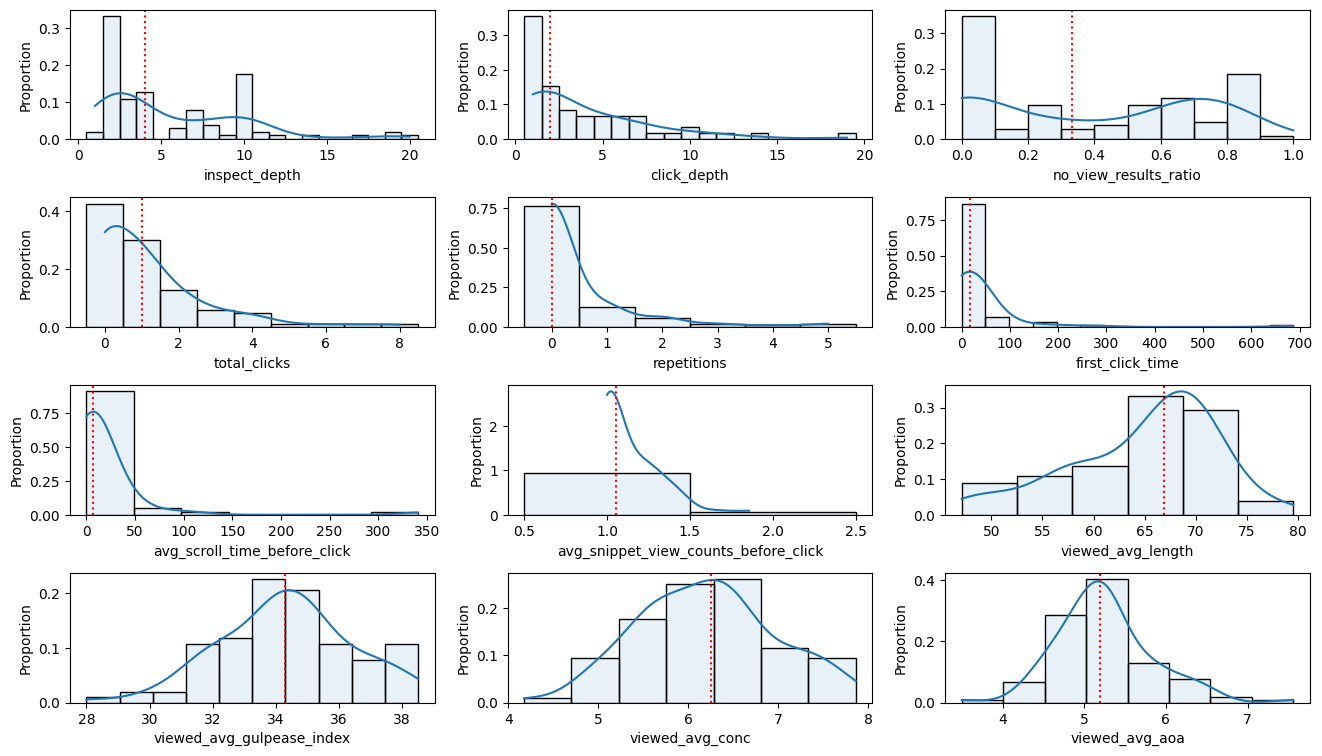

,category,mean,std_dev,max,min,median,modes
0,inspect_depth,5.617647,4.286853,20.000000,1.000000,4.000000,[2.0]
1,click_depth,3.983051,3.798782,19.000000,1.000000,2.000000,[1.0]
2,no_view_results_ratio,0.383634,0.335303,1.000000,0.000000,0.333333,[0.0]
3,total_clicks,1.174757,1.561969,8.000000,0.000000,1.000000,[0]
4,repetitions,0.436893,0.996759,5.000000,0.000000,0.000000,[0]
5,first_click_time,41.202780,97.996383,687.110000,0.149000,17.083000,"[0.149, 0.172, 1.924, 2.288, 2.454, 3.376, 4.0..."
6,avg_scroll_time_before_click,18.623926,48.068321,341.061000,0.002000,7.046200,[0.003]
7,avg_snippet_view_counts_before_click,1.142713,0.188576,1.857143,1.000000,1.052778,[1.0]
8,viewed_avg_length,64.888723,7.198763,79.525876,47.114628,66.920593,[70.00657894736842]
9,viewed_avg_gulpease_index,34.326479,2.100241,38.500000,28.000000,34.292857,"[34.0, 35.0]"


In [35]:
from driver import get_descriptive_stats
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")

binwidth_map = {
    "first_click_time": 50,
    "avg_scroll_time_before_click": 50,
    "avg_snippet_dwell_time_before_click": 10,
    "avg_snippet_view_counts_before_click": 0.1,
    "inspect_depth": 1,
    "viewed_avg_length": 5,
    "viewed_avg_gulpease_index": 1,
    "viewed_avg_conc": 0.5,
    "viewed_avg_aoa": 0.5,
    "SERP_avg_length": 5,
    "SERP_avg_gulpease_index": 1,
    "SERP_avg_conc": 0.5,
    "SERP_avg_aoa": 0.5,
    "no_view_results_ratio": 0.1,
    "repetitions": 1,
    "tail": 1,
    "SERP_total_results": 1,
    "SERP_highest_rel_result": 1,
    "total_clicks": 1,
    "click_depth":1
}

desc_stats = get_descriptive_stats(df=navigation_quality, search_stage="results_navigation", categories=categories, ncols=3, nrows=4, binwidth_map=binwidth_map)
desc_stats

In [36]:
results_navigation = pd.read_csv("Data/results_navigation.csv")
len(results_navigation.loc[results_navigation["click_count"]>1]), len(results_navigation.loc[results_navigation["click_count"]==1]), len(results_navigation)

(31, 90, 930)

In [37]:
import pandas as pd
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
len(navigation_quality.loc[navigation_quality["total_clicks"]==0])/len(navigation_quality)

0.42718446601941745

In [38]:
import pandas as pd
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
len(navigation_quality.loc[navigation_quality["total_clicks"]==0])/len(navigation_quality)

0.42718446601941745

In [39]:
len(navigation_quality.loc[navigation_quality["first_click_time"]<=60])/len(navigation_quality.loc[navigation_quality["total_clicks"]>0])

0.8813559322033898

In [40]:
len(navigation_quality.loc[navigation_quality["avg_scroll_time_before_click"]<=18])/len(navigation_quality.loc[navigation_quality["total_clicks"]>0])


0.7627118644067796

In [41]:
len(navigation_quality.loc[navigation_quality["avg_scroll_time_before_click"]<=50])/len(navigation_quality[~pd.isna(navigation_quality["avg_scroll_time_before_click"])])

0.9122807017543859

In [42]:
len(navigation_quality.loc[navigation_quality["avg_snippet_dwell_time_before_click"]<=15])/len(navigation_quality.loc[navigation_quality["total_clicks"]>0])

0.7966101694915254

In [43]:
len(navigation_quality.loc[navigation_quality["rank_lowest_view"]<=5])/len(navigation_quality)


0.5825242718446602

In [44]:
len(navigation_quality.loc[navigation_quality["rank_lowest_view"]<=10])/len(navigation_quality)

0.912621359223301

In [45]:
len(navigation_quality.loc[navigation_quality["no_view_results_ratio"]>=0.8])/len(navigation_quality)

0.1941747572815534

In [46]:
len(navigation_quality.loc[navigation_quality["SERP_avg_gulpease_index"]>=80])/len(navigation_quality)

0.0

In [47]:
results_navigation = pd.read_csv("Data/results_navigation.csv")
len(results_navigation.loc[results_navigation["SERP_result_gulpease_index"]>=80])/len(results_navigation)

0.13870967741935483

In [48]:
len(navigation_quality)

103

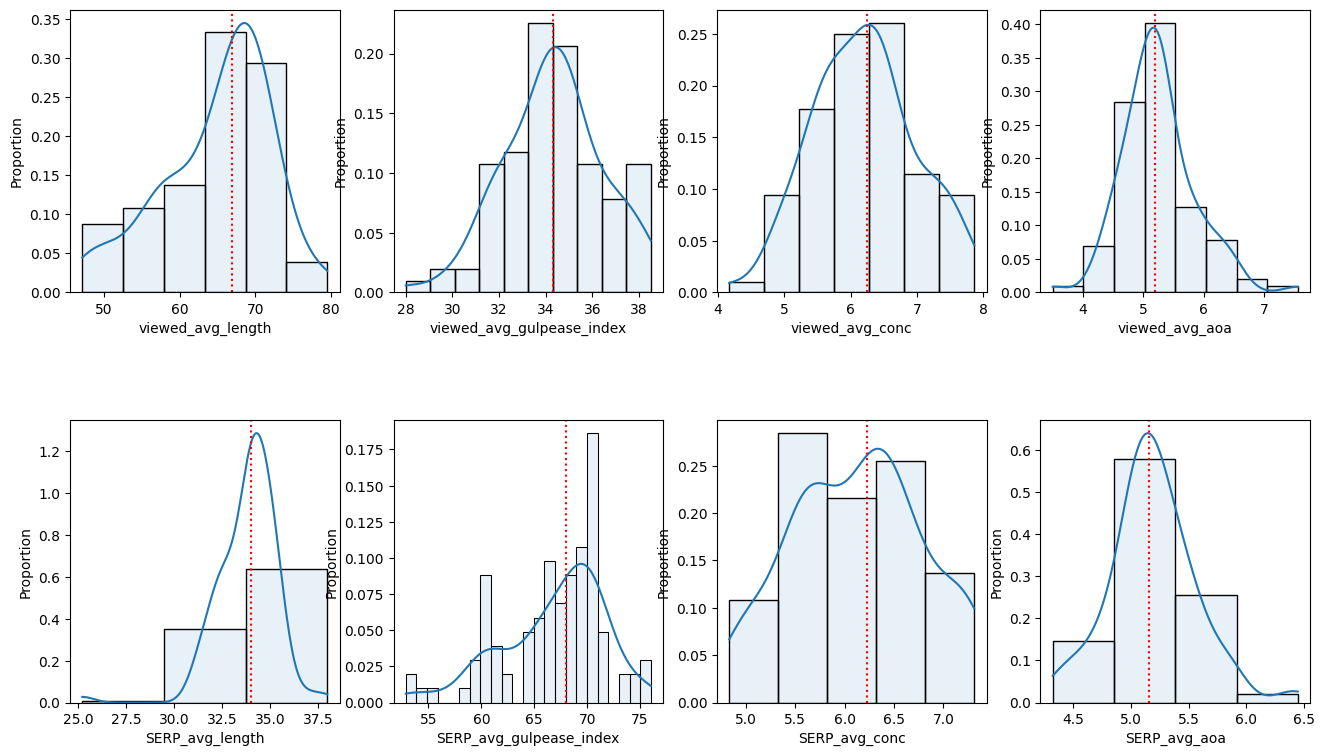

,category,mean,std_dev,max,min,median,modes
0,viewed_avg_length,64.888723,7.198763,79.525876,47.114628,66.920593,[70.00657894736842]
1,viewed_avg_gulpease_index,34.326479,2.100241,38.500000,28.000000,34.292857,"[34.0, 35.0]"
2,viewed_avg_conc,6.205167,0.761402,7.862500,4.175000,6.249722,[5.578125]
3,viewed_avg_aoa,5.251159,0.595631,7.560000,3.500000,5.192867,[5.155777777777778]
4,SERP_avg_length,33.829326,1.554779,38.000000,25.200000,34.000000,"[32.4, 34.166666666666664]"
5,SERP_avg_gulpease_index,66.857674,4.861752,76.016256,52.852774,68.041636,[70.37789978631228]
6,SERP_avg_conc,6.133167,0.655358,7.312500,4.833333,6.223590,"[5.0, 5.578125]"
7,SERP_avg_aoa,5.191166,0.376422,6.446067,4.320000,5.155778,[5.155777777777778]


In [49]:
from driver import get_descriptive_stats

extra_categories = [
    # "first_click_time", "avg_scroll_time_before_click", "avg_snippet_dwell_time_before_click", "avg_snippet_view_counts_before_click", "rank_lowest_view", 
    # "repetitions", "tail", 
    # "SERP_total_results", "SERP_highest_rel_result",
    "viewed_avg_length", 
    "viewed_avg_gulpease_index", 
    "viewed_avg_conc", 
    "viewed_avg_aoa", 
    "SERP_avg_length", "SERP_avg_gulpease_index", "SERP_avg_conc", "SERP_avg_aoa"
    # "no_view_results_ratio"
]

binwidth_map = {
    "first_click_time": 50,
    "avg_scroll_time_before_click": 50,
    "avg_snippet_dwell_time_before_click": 10,
    "avg_snippet_view_counts_before_click": 0.1,
    "rank_lowest_view": 1,
    "viewed_avg_length": 5,
    "viewed_avg_gulpease_index": 1,
    "viewed_avg_conc": 0.5,
    "viewed_avg_aoa": 0.5,
    "SERP_avg_length": 5,
    "SERP_avg_gulpease_index": 1,
    "SERP_avg_conc": 0.5,
    "SERP_avg_aoa": 0.5,
    "no_view_results_ratio": 0.1,
    "repetitions": 1,
    "tail": 1,
    "click_depth": 1,
    "SERP_total_results": 1,
    "SERP_highest_rel_result": 1
}

desc_stats = get_descriptive_stats(df=navigation_quality.loc[navigation_quality["no_view_results_ratio"]<1], search_stage="results_navigation_extra", categories=extra_categories, ncols=4, nrows=2, binwidth_map=binwidth_map)
desc_stats

In [50]:
results_navigation.head()

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index,view_count
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","Oct 31, 2023 ... La fauna selvatica dell'India...",1,1,2,2026-05-19 14:51:27.687,"India naturalistica, 5 animali da non perdere ...",34,6.270000,7.875000,58.022989,3
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","Feb 17, 2017 ... O dei Giganti, vista la mole ...",2,1,0,2026-05-19 14:51:27.688,"Natura selvaggia in India, tra tigri e leoni -...",36,6.864000,5.666667,66.250000,3
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","Jun 5, 2023 ... Sono note cinque metropoli, tr...",3,0,0,2026-05-19 14:51:27.689,"La civiltà dell'Indo, i misteri di un popolo d...",32,NaN,NaN,65.363636,3
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","Jun 6, 2024 ... Chi sono, da dove vengono e qu...",4,0,0,2026-05-19 14:51:27.690,"Chi sono gli Indiani d'America, i nativi ameri...",33,NaN,NaN,61.536765,2
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,Il dolce tipico per celebrare questo giorno è ...,5,0,0,2026-05-19 14:51:27.691,Festa della mamma: come si festeggia nel resto...,37,3.914286,7.200000,64.444015,1


In [51]:
len(navigation_quality.loc[navigation_quality["no_view_results_ratio"]==1])

1

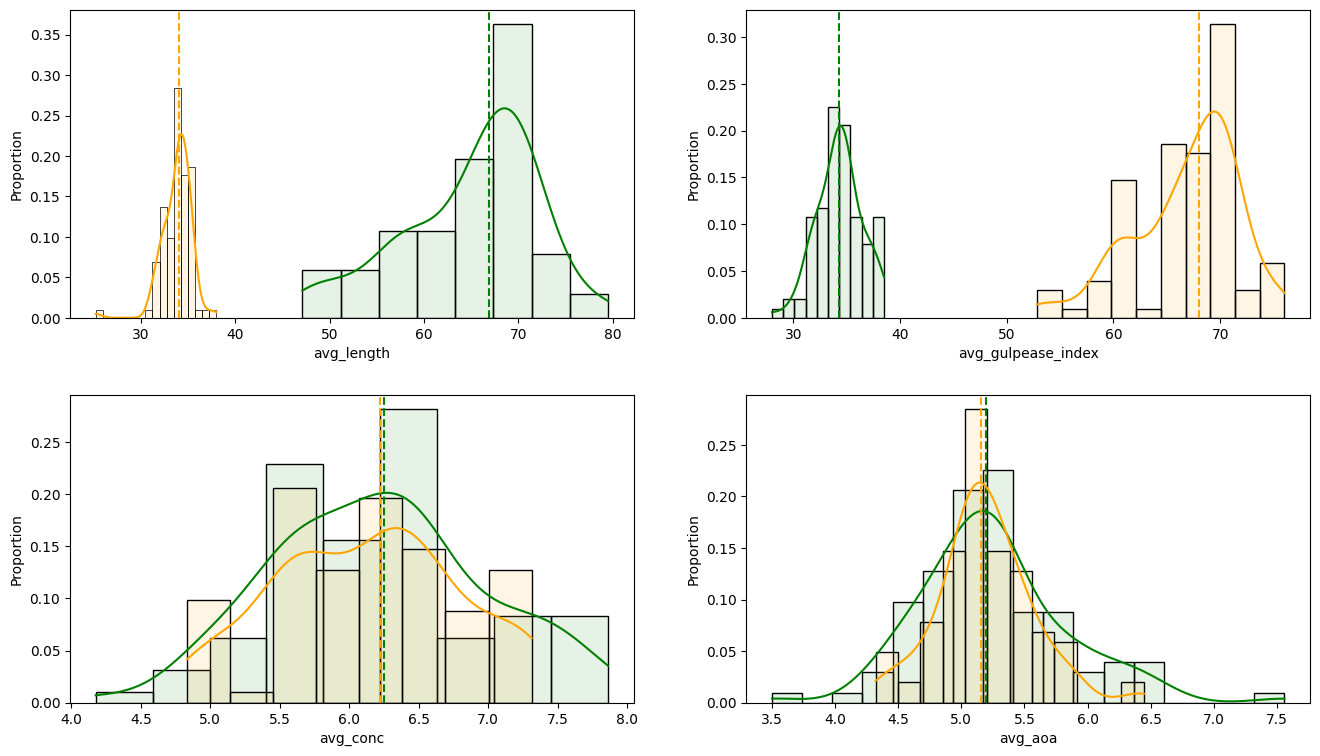

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")
df = navigation_quality.loc[navigation_quality["no_view_results_ratio"]<1] # children viewed at least one result
# results_navigation = pd.read_csv("Data/results_navigation.csv")
# viewed_results = results_navigation.loc[results_navigation["view_count"]>0]
# not_viewed_results = results_navigation.loc[results_navigation["view_count"]==0]
# print(len(df))
binwidth_map = {
    "viewed_avg_length": 5,
    "viewed_avg_gulpease_index": 1,
    "viewed_avg_conc": 0.5,
    "viewed_avg_aoa": 0.5,
    "SERP_avg_length": 5,
    "SERP_avg_gulpease_index": 1,
    "SERP_avg_conc": 0.5,
    "SERP_avg_aoa": 0.5,
}
plt.figure(figsize=(16,9))
plt.subplots_adjust(hspace=0.25)
ncols = 2
nrows = 2
for i, category in enumerate(["avg_length", "avg_gulpease_index", "avg_conc", "avg_aoa"]):
# for i, category in enumerate(["SERP_result_content_len", "SERP_result_mean_aoa", "SERP_result_mean_conc", "SERP_result_gulpease_index"]):
    ax = plt.subplot(nrows, ncols, i+1)
    viewed = df["viewed_"+category]
    not_viewed = df["no_view_"+category]
    SERP = df["SERP_"+category]
    sns.histplot(
            data=viewed,
            stat="proportion",
            ax = ax,
            alpha=0.1,
            kde=True,
            kde_kws={"cut":0},
            color="green",
            label="Viewed results"
        )
    viewed_median = viewed.median()
    ax.axvline(viewed_median, linestyle="--", color="green", label="median value for viewed results")

    # sns.histplot(
    #         data=not_viewed,
    #         stat="proportion",
    #         ax = ax,
    #         alpha=0.1,
    #         kde=True,
    #         kde_kws={"cut":0},
    #         color="green",
    #         label="avg of not viewed results"
    #     )
    # not_viewed_median = not_viewed.median()
    # ax.axvline(not_viewed_median, linestyle="--", color="green", label="not_viewed_median")

    sns.histplot(
            data=SERP,
            stat="proportion",
            ax=ax,
            alpha=0.1,
            kde=True,
            kde_kws={"cut":0},
            color="orange",
            label="All SERP results"
        )
    SERP_median = SERP.median()
    ax.axvline(SERP_median, linestyle="--", color="orange", label="median value for all SERP results")
    ax.set_xlabel(category)
# handles, labels = ax.get_legend_handles_labels()
# plt.figlegend(handles, labels, loc="upper center", ncol=6, fontsize=10)
plt.savefig("Figures/viewed_vs_SERP_results.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [53]:
results_navigation = pd.read_csv("Data/results_navigation.csv")
results_navigation.head()
# rank_wise = results_navigation.groupby("rank")[["SERP_result_content_len", "SERP_result_mean_aoa", "SERP_result_mean_conc", "SERP_result_gulpease_index"]].mean().reset_index(drop=False)
# nrows = 2
# ncols = 2
# plt.figure(figsize=(16,9))
# plt.subplots_adjust(hspace=0.25)
# for i, category in enumerate(["SERP_result_content_len", "SERP_result_mean_aoa", "SERP_result_mean_conc", "SERP_result_gulpease_index"]):
#     ax = plt.subplot(nrows, ncols, i+1)
#     sns.barplot(
#             data=rank_wise,
#             x = "rank",
#             y = category,
#             ax = ax,
#         )

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index,view_count
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","Oct 31, 2023 ... La fauna selvatica dell'India...",1,1,2,2026-05-19 14:51:27.687,"India naturalistica, 5 animali da non perdere ...",34,6.270000,7.875000,58.022989,3
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","Feb 17, 2017 ... O dei Giganti, vista la mole ...",2,1,0,2026-05-19 14:51:27.688,"Natura selvaggia in India, tra tigri e leoni -...",36,6.864000,5.666667,66.250000,3
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","Jun 5, 2023 ... Sono note cinque metropoli, tr...",3,0,0,2026-05-19 14:51:27.689,"La civiltà dell'Indo, i misteri di un popolo d...",32,NaN,NaN,65.363636,3
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","Jun 6, 2024 ... Chi sono, da dove vengono e qu...",4,0,0,2026-05-19 14:51:27.690,"Chi sono gli Indiani d'America, i nativi ameri...",33,NaN,NaN,61.536765,2
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,Il dolce tipico per celebrare questo giorno è ...,5,0,0,2026-05-19 14:51:27.691,Festa della mamma: come si festeggia nel resto...,37,3.914286,7.200000,64.444015,1


### RQ2

In [54]:
len(navigation_quality), len(navigation_quality.loc[navigation_quality["effective_navigation"]==1])

(103, 45)

In [55]:
from driver import get_significance

categories = [
    "inspect_depth", "click_depth", "no_view_results_ratio", "total_clicks", "repetitions",
    "first_click_time", "avg_scroll_time_before_click", 
    # "avg_snippet_dwell_time_before_click", 
    "avg_snippet_view_counts_before_click", 
    # "tail", 
    # "SERP_total_results", 
    
    # "SERP_highest_rel_result",
    "viewed_avg_length", #"SERP_avg_length", 
    "viewed_avg_gulpease_index", #"SERP_avg_gulpease_index", 
    "viewed_avg_conc", #"SERP_avg_conc", 
    "viewed_avg_aoa", #"SERP_avg_aoa", 
    
]

desc_stats_df_tail_ratio, sig_test_results_tail_ratio = get_significance(df=navigation_quality, effective_label="effective_navigation", search_stage="results_navigation", categories=categories)
sig_test_results_tail_ratio

,search_stage,characteristic,test_statistic,pval,significant
0,results_navigation,inspect_depth,1.000000,0.4478,False
1,results_navigation,click_depth,5.000000,0.0002,True
2,results_navigation,no_view_results_ratio,-0.066667,0.9260,False
3,results_navigation,total_clicks,-1.000000,0.0582,False
4,results_navigation,repetitions,0.000000,1.0000,False
5,results_navigation,first_click_time,11.778000,0.0264,True
6,results_navigation,avg_scroll_time_before_click,4.557500,0.2006,False
7,results_navigation,avg_snippet_view_counts_before_click,0.100000,0.1722,False
8,results_navigation,viewed_avg_length,2.960218,0.0436,True
9,results_navigation,viewed_avg_gulpease_index,-0.399123,0.6238,False


In [56]:
desc_stats_df_tail_ratio

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,results_navigation,inspect_depth,4.000000,2.000000,3.000000,1.000000
1,results_navigation,click_depth,6.000000,2.000000,1.000000,0.000000
2,results_navigation,no_view_results_ratio,0.333333,0.333333,0.400000,0.400000
3,results_navigation,total_clicks,0.000000,0.000000,1.000000,0.000000
4,results_navigation,repetitions,0.000000,0.000000,0.000000,0.000000
5,results_navigation,first_click_time,22.658000,11.920000,10.880000,7.111000
6,results_navigation,avg_scroll_time_before_click,7.727600,3.961267,3.170100,3.167600
7,results_navigation,avg_snippet_view_counts_before_click,1.100000,0.100000,1.000000,0.000000
8,results_navigation,viewed_avg_length,67.700040,3.001200,64.739822,5.266757
9,results_navigation,viewed_avg_gulpease_index,34.166667,1.333333,34.565789,1.422932


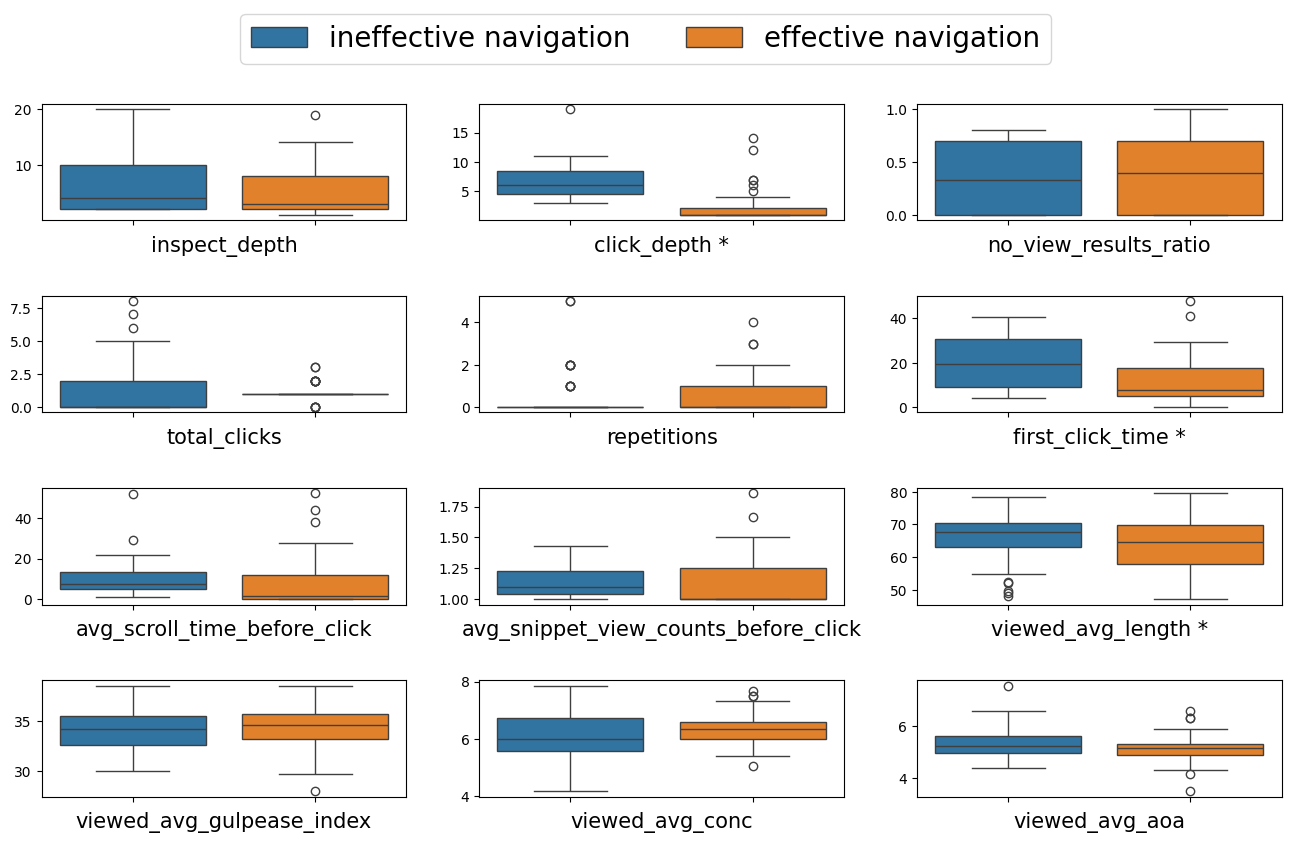

In [57]:
from driver import get_boxplots

get_boxplots(df=navigation_quality, search_stage="results_navigation", categories=categories, group="effective_navigation", artefact="navigation", n_cols=3, n_rows=4, stats_df=sig_test_results_tail_ratio)